# Assignment 2 – Part 2: U-Net vs U-Net++ for Image Segmentation

**Student ID:** 26K-7618

**Use case:** Pet segmentation. Given a photo of a cat or dog, the model marks every pixel as **pet** or **background**.

**Dataset:** [Oxford-IIIT Pet](https://www.robots.ox.ac.uk/~vgg/data/pets/) (about 7,400 images of 37 breeds, each with a pixel-level mask).

### What this notebook does
1. Loads and prepares the data
2. Builds **U-Net** from scratch
3. Builds **U-Net++** from scratch
4. Trains both models the same way (same data, loss, optimizer and epochs) so the comparison is fair
5. Compares them using **IoU**, **Dice score**, model size and training time
6. Shows predictions side by side

**Environment:** PyTorch, trained on an Apple M4 Pro GPU (MPS backend). The same notebook also runs on an NVIDIA GPU (for example Google Colab).

## 1. Setup

In [1]:
import time
import random

import numpy as np
import matplotlib.pyplot as plt
import torch
import torch.nn as nn
from torch.utils.data import Dataset, DataLoader, Subset
from torchvision import datasets
from torchvision.transforms import InterpolationMode
import torchvision.transforms.functional as TF

All the settings are kept in one place, so we can change an experiment without searching through the code.

In [2]:
IMAGE_SIZE = 128        # images are resized to 128x128 to keep training fast
BATCH_SIZE = 16
EPOCHS = 15
LEARNING_RATE = 1e-3
VAL_FRACTION = 0.15     # 15% of the training images are kept aside for validation
SEED = 42

if torch.cuda.is_available():
    device = "cuda"
elif torch.backends.mps.is_available():   # Apple Silicon Mac
    device = "mps"
else:
    device = "cpu"

# Background data loading (num_workers > 0) only works reliably on Linux/Colab.
# On a Mac inside Jupyter it crashes, so we load data in the main process there.
NUM_WORKERS = 2 if device == "cuda" else 0

print("Using device:", device)

Using device: mps


Fixing the random seed makes the results repeatable: running the notebook again gives (almost) the same numbers.

In [3]:
def set_seed(seed):
    random.seed(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)
    torch.cuda.manual_seed_all(seed)

set_seed(SEED)

## 2. Data

Each image in the dataset comes with a **trimap**, a mask where every pixel has one of three values:

| Value | Meaning |
|---|---|
| 1 | pet |
| 2 | background |
| 3 | border (the edge around the pet) |

We turn this into a simple **binary mask**: pet + border = `1`, background = `0`.

Steps for every image:
- resize the image and the mask to 128×128 (the mask uses **nearest** resizing so the values stay 0/1 and don't get blurred)
- for training only, randomly flip the image left-right (**data augmentation**). This shows the model more variety and reduces overfitting. The mask is flipped too, so it still matches the image.

In [4]:
class PetDataset(Dataset):
    def __init__(self, split, train=False):
        # split is "trainval" or "test"
        self.data = datasets.OxfordIIITPet(
            root="data",
            split=split,
            target_types="segmentation",
            download=True,
        )
        self.train = train

    def __len__(self):
        return len(self.data)

    def __getitem__(self, index):
        image, trimap = self.data[index]

        image = TF.resize(image, [IMAGE_SIZE, IMAGE_SIZE])
        trimap = TF.resize(trimap, [IMAGE_SIZE, IMAGE_SIZE], interpolation=InterpolationMode.NEAREST)

        if self.train and random.random() < 0.5:
            image = TF.hflip(image)
            trimap = TF.hflip(trimap)

        image = TF.to_tensor(image)                       # shape (3, H, W), values 0..1
        trimap = torch.from_numpy(np.array(trimap))       # shape (H, W), values 1, 2, 3
        mask = (trimap != 2).float().unsqueeze(0)         # shape (1, H, W), 1 = pet, 0 = background

        return image, mask

The dataset has a `trainval` split and a `test` split. We divide `trainval` into **train** and **validation**:
- **train** is what the model learns from
- **validation** is checked after every epoch to choose the best model
- **test** is used only once at the very end, for the final fair score

Two copies of the trainval dataset are made, one with flipping on and one with it off, so the validation images are never augmented.

In [5]:
train_full = PetDataset("trainval", train=True)
val_full = PetDataset("trainval", train=False)
test_data = PetDataset("test", train=False)

indices = list(range(len(train_full)))
random.shuffle(indices)
val_size = int(len(indices) * VAL_FRACTION)

train_data = Subset(train_full, indices[val_size:])
val_data = Subset(val_full, indices[:val_size])

train_loader = DataLoader(train_data, batch_size=BATCH_SIZE, shuffle=True, num_workers=NUM_WORKERS)
val_loader = DataLoader(val_data, batch_size=BATCH_SIZE, shuffle=False, num_workers=NUM_WORKERS)
test_loader = DataLoader(test_data, batch_size=BATCH_SIZE, shuffle=False, num_workers=NUM_WORKERS)

print("Train images:", len(train_data))
print("Val images:  ", len(val_data))
print("Test images: ", len(test_data))

Train images: 3128
Val images:   552
Test images:  3669


Always look at the data before training. Here we check that the masks really match the pets.

Image batch shape: torch.Size([16, 3, 128, 128])
Mask batch shape:  torch.Size([16, 1, 128, 128])


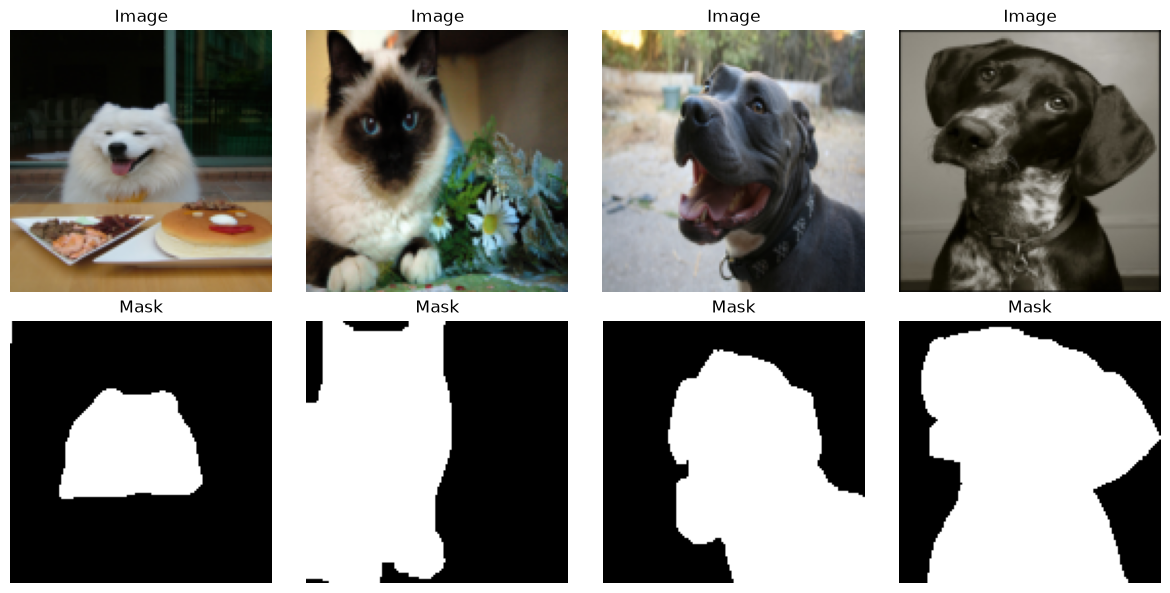

In [6]:
images, masks = next(iter(train_loader))
print("Image batch shape:", images.shape)   # (batch, 3, H, W)
print("Mask batch shape: ", masks.shape)    # (batch, 1, H, W)

fig, axes = plt.subplots(2, 4, figsize=(12, 6))
for i in range(4):
    axes[0, i].imshow(images[i].permute(1, 2, 0))
    axes[0, i].set_title("Image")
    axes[1, i].imshow(masks[i, 0], cmap="gray")
    axes[1, i].set_title("Mask")
for ax in axes.flat:
    ax.axis("off")
plt.tight_layout()
plt.show()

## 3. The building block

Both U-Net and U-Net++ are built from the same small block, used again and again:

**Conv 3×3 → BatchNorm → ReLU → Conv 3×3 → BatchNorm → ReLU**

- `padding=1` keeps the height and width the same, so only the number of channels changes
- **BatchNorm** keeps the values in a stable range, which makes training faster and smoother
- `bias=False` is used because BatchNorm already adds its own bias

Writing it once as a class and reusing it keeps both models short and easy to read.

In [7]:
class DoubleConv(nn.Module):
    def __init__(self, in_channels, out_channels):
        super().__init__()
        self.block = nn.Sequential(
            nn.Conv2d(in_channels, out_channels, kernel_size=3, padding=1, bias=False),
            nn.BatchNorm2d(out_channels),
            nn.ReLU(inplace=True),
            nn.Conv2d(out_channels, out_channels, kernel_size=3, padding=1, bias=False),
            nn.BatchNorm2d(out_channels),
            nn.ReLU(inplace=True),
        )

    def forward(self, x):
        return self.block(x)

## 4. U-Net

U-Net (Ronneberger et al., 2015) has a "U" shape:

```
 input ─ enc1 ──────────────────────────────── dec1 ─ output
           └─ enc2 ──────────────────── dec2 ─┘
                └─ enc3 ──────── dec3 ─┘
                     └─ enc4 ─ dec4 ─┘
                          bottleneck
```

- **Encoder (left side):** each step halves the image size (MaxPool) and doubles the channels. The model learns **what** is in the image but loses detail about **where**.
- **Decoder (right side):** each step doubles the size again (Upsample) to get back to the full-size mask.
- **Skip connections (horizontal lines):** the encoder output at each level is joined (`torch.cat`) with the decoder at the same level. This gives the decoder back the fine details (edges, outlines) that were lost while shrinking.

The last layer is a 1×1 convolution that gives **one number per pixel**. Higher means "more likely pet".

With `IMAGE_SIZE = 128` the sizes go: 128 → 64 → 32 → 16 → 8 (bottleneck) → 16 → 32 → 64 → 128.

In [8]:
class UNet(nn.Module):
    def __init__(self, in_channels=3, out_channels=1, filters=(32, 64, 128, 256, 512)):
        super().__init__()
        f = filters
        self.pool = nn.MaxPool2d(2)
        self.up = nn.Upsample(scale_factor=2, mode="bilinear", align_corners=True)

        # encoder
        self.enc1 = DoubleConv(in_channels, f[0])
        self.enc2 = DoubleConv(f[0], f[1])
        self.enc3 = DoubleConv(f[1], f[2])
        self.enc4 = DoubleConv(f[2], f[3])
        self.bottleneck = DoubleConv(f[3], f[4])

        # decoder: input channels = upsampled channels + skip connection channels
        self.dec4 = DoubleConv(f[4] + f[3], f[3])
        self.dec3 = DoubleConv(f[3] + f[2], f[2])
        self.dec2 = DoubleConv(f[2] + f[1], f[1])
        self.dec1 = DoubleConv(f[1] + f[0], f[0])

        self.final = nn.Conv2d(f[0], out_channels, kernel_size=1)

    def forward(self, x):
        # going down
        e1 = self.enc1(x)
        e2 = self.enc2(self.pool(e1))
        e3 = self.enc3(self.pool(e2))
        e4 = self.enc4(self.pool(e3))
        b = self.bottleneck(self.pool(e4))

        # going up, joining with the skip connection at each level
        d4 = self.dec4(torch.cat([self.up(b), e4], dim=1))
        d3 = self.dec3(torch.cat([self.up(d4), e3], dim=1))
        d2 = self.dec2(torch.cat([self.up(d3), e2], dim=1))
        d1 = self.dec1(torch.cat([self.up(d2), e1], dim=1))

        return self.final(d1)

## 5. U-Net++

U-Net++ (Zhou et al., 2018) keeps the same encoder but changes the skip connections.

**The problem with U-Net:** the skip connection joins encoder features (early, simple: edges and colours) directly with decoder features (late, deep: "this is a dog"). These are very different kinds of information, which the paper calls a **semantic gap**.

**The U-Net++ fix:** instead of one direct jump, each skip path goes through a few extra conv blocks first. Every block takes **all earlier blocks at its level** plus the upsampled block from **one level below** (these are the *dense* and *nested* skip connections).

### Naming: `x{i}_{j}` (same as the paper's X<sup>i,j</sup>)
- `i` = the level (0 = full size, 4 = smallest)
- `j` = the column (0 = encoder, higher = further right)

```
x0_0 ── x0_1 ── x0_2 ── x0_3 ── x0_4 → output
   x1_0 ── x1_1 ── x1_2 ── x1_3
      x2_0 ── x2_1 ── x2_2
         x3_0 ── x3_1
            x4_0
```

The rule for each block:
`x{i}_{j} = DoubleConv( cat[ x{i}_0, x{i}_1, ..., x{i}_{j-1}, up(x{i+1}_{j-1}) ] )`

That's why the input channels grow along a row: `x0_1` gets `f[0] + f[1]`, `x0_2` gets `2*f[0] + f[1]`, `x0_3` gets `3*f[0] + f[1]` and so on.

The forward pass below is written column by column, in the same order the paper's diagram fills in.

In [9]:
class UNetPlusPlus(nn.Module):
    def __init__(self, in_channels=3, out_channels=1, filters=(32, 64, 128, 256, 512)):
        super().__init__()
        f = filters
        self.pool = nn.MaxPool2d(2)
        self.up = nn.Upsample(scale_factor=2, mode="bilinear", align_corners=True)

        # column 0: the encoder (same as U-Net)
        self.conv0_0 = DoubleConv(in_channels, f[0])
        self.conv1_0 = DoubleConv(f[0], f[1])
        self.conv2_0 = DoubleConv(f[1], f[2])
        self.conv3_0 = DoubleConv(f[2], f[3])
        self.conv4_0 = DoubleConv(f[3], f[4])

        # column 1
        self.conv0_1 = DoubleConv(f[0] + f[1], f[0])
        self.conv1_1 = DoubleConv(f[1] + f[2], f[1])
        self.conv2_1 = DoubleConv(f[2] + f[3], f[2])
        self.conv3_1 = DoubleConv(f[3] + f[4], f[3])

        # column 2
        self.conv0_2 = DoubleConv(f[0] * 2 + f[1], f[0])
        self.conv1_2 = DoubleConv(f[1] * 2 + f[2], f[1])
        self.conv2_2 = DoubleConv(f[2] * 2 + f[3], f[2])

        # column 3
        self.conv0_3 = DoubleConv(f[0] * 3 + f[1], f[0])
        self.conv1_3 = DoubleConv(f[1] * 3 + f[2], f[1])

        # column 4
        self.conv0_4 = DoubleConv(f[0] * 4 + f[1], f[0])

        self.final = nn.Conv2d(f[0], out_channels, kernel_size=1)

    def forward(self, x):
        x0_0 = self.conv0_0(x)
        x1_0 = self.conv1_0(self.pool(x0_0))
        x0_1 = self.conv0_1(torch.cat([x0_0, self.up(x1_0)], dim=1))

        x2_0 = self.conv2_0(self.pool(x1_0))
        x1_1 = self.conv1_1(torch.cat([x1_0, self.up(x2_0)], dim=1))
        x0_2 = self.conv0_2(torch.cat([x0_0, x0_1, self.up(x1_1)], dim=1))

        x3_0 = self.conv3_0(self.pool(x2_0))
        x2_1 = self.conv2_1(torch.cat([x2_0, self.up(x3_0)], dim=1))
        x1_2 = self.conv1_2(torch.cat([x1_0, x1_1, self.up(x2_1)], dim=1))
        x0_3 = self.conv0_3(torch.cat([x0_0, x0_1, x0_2, self.up(x1_2)], dim=1))

        x4_0 = self.conv4_0(self.pool(x3_0))
        x3_1 = self.conv3_1(torch.cat([x3_0, self.up(x4_0)], dim=1))
        x2_2 = self.conv2_2(torch.cat([x2_0, x2_1, self.up(x3_1)], dim=1))
        x1_3 = self.conv1_3(torch.cat([x1_0, x1_1, x1_2, self.up(x2_2)], dim=1))
        x0_4 = self.conv0_4(torch.cat([x0_0, x0_1, x0_2, x0_3, self.up(x1_3)], dim=1))

        return self.final(x0_4)

### Sanity check before training

Before spending time on training, pass a random fake image through each model and check:
1. the output has the same height and width as the input (one value per pixel)
2. how many parameters (learnable weights) each model has

This catches shape mistakes in seconds instead of after a crash in training.

In [10]:
def count_parameters(model):
    return sum(p.numel() for p in model.parameters())

fake_images = torch.randn(2, 3, IMAGE_SIZE, IMAGE_SIZE)

for model in [UNet(), UNetPlusPlus()]:
    output = model(fake_images)
    assert output.shape == (2, 1, IMAGE_SIZE, IMAGE_SIZE)
    print(f"{model.__class__.__name__:13s} output {tuple(output.shape)}   parameters: {count_parameters(model):,}")

UNet          output (2, 1, 128, 128)   parameters: 7,849,601
UNetPlusPlus  output (2, 1, 128, 128)   parameters: 9,159,681


## 6. Loss and metrics

### Loss (what the model minimises during training)
We add two losses together:
- **BCE (Binary Cross-Entropy):** checks every pixel on its own. Was it pet or not?
- **Dice loss:** looks at the overlap of the whole predicted shape with the true shape. It helps when the pet covers only a small part of the image, where BCE alone could score well by just predicting "background" everywhere.

`BCEWithLogitsLoss` applies the sigmoid itself, so the model outputs raw scores (called *logits*).

### Metrics (how we judge the result)
A pixel counts as "pet" if its probability is above 0.5.
- **IoU (Intersection over Union)** = overlap ÷ total area covered by either mask
- **Dice** = 2 × overlap ÷ (predicted area + true area)

Both range from 0 (no overlap) to 1 (perfect). Dice is always a bit higher than IoU for the same prediction.

In [11]:
bce_loss = nn.BCEWithLogitsLoss()

def dice_loss(logits, masks, smooth=1.0):
    probs = torch.sigmoid(logits)
    intersection = (probs * masks).sum(dim=(1, 2, 3))
    total = probs.sum(dim=(1, 2, 3)) + masks.sum(dim=(1, 2, 3))
    dice = (2 * intersection + smooth) / (total + smooth)
    return 1 - dice.mean()

def loss_fn(logits, masks):
    return bce_loss(logits, masks) + dice_loss(logits, masks)


def iou_and_dice(logits, masks):
    preds = (torch.sigmoid(logits) > 0.5).float()
    intersection = (preds * masks).sum(dim=(1, 2, 3))
    pred_area = preds.sum(dim=(1, 2, 3))
    true_area = masks.sum(dim=(1, 2, 3))

    iou = (intersection + 1e-6) / (pred_area + true_area - intersection + 1e-6)
    dice = (2 * intersection + 1e-6) / (pred_area + true_area + 1e-6)
    return iou.mean().item(), dice.mean().item()

## 7. Training

The same functions train both models. This is important for a fair comparison: the only thing that changes is the architecture.

- `train_one_epoch`: one full pass over the training data, updating the weights
- `evaluate`: measures loss, IoU and Dice **without** updating weights (`model.eval()` + `torch.no_grad()`)
- `train_model`: runs both for every epoch, and **saves the model whenever validation Dice improves**. At the end we load the best saved version, not just the last one, which protects us from overfitting in later epochs.

In [12]:
def train_one_epoch(model, loader, optimizer):
    model.train()
    total_loss = 0
    for images, masks in loader:
        images, masks = images.to(device), masks.to(device)

        logits = model(images)
        loss = loss_fn(logits, masks)

        optimizer.zero_grad()
        loss.backward()
        optimizer.step()

        total_loss += loss.item()
    return total_loss / len(loader)


@torch.no_grad()
def evaluate(model, loader):
    model.eval()
    total_loss, total_iou, total_dice = 0, 0, 0
    for images, masks in loader:
        images, masks = images.to(device), masks.to(device)
        logits = model(images)

        total_loss += loss_fn(logits, masks).item()
        iou, dice = iou_and_dice(logits, masks)
        total_iou += iou
        total_dice += dice

    n = len(loader)
    return total_loss / n, total_iou / n, total_dice / n


def train_model(model, name, epochs=EPOCHS):
    set_seed(SEED)   # same starting conditions for every model
    model = model.to(device)
    optimizer = torch.optim.Adam(model.parameters(), lr=LEARNING_RATE)

    history = {"train_loss": [], "val_loss": [], "val_iou": [], "val_dice": []}
    best_dice = -1   # so the first epoch is always saved
    save_path = f"{name}_best.pt"
    start = time.time()

    for epoch in range(1, epochs + 1):
        train_loss = train_one_epoch(model, train_loader, optimizer)
        val_loss, val_iou, val_dice = evaluate(model, val_loader)

        history["train_loss"].append(train_loss)
        history["val_loss"].append(val_loss)
        history["val_iou"].append(val_iou)
        history["val_dice"].append(val_dice)

        saved = ""
        if val_dice > best_dice:
            best_dice = val_dice
            torch.save(model.state_dict(), save_path)
            saved = "  <- saved"

        print(f"Epoch {epoch:2d}/{epochs} | train loss {train_loss:.4f} | "
              f"val loss {val_loss:.4f} | val IoU {val_iou:.4f} | val Dice {val_dice:.4f}{saved}")

    minutes = (time.time() - start) / 60
    print(f"Done in {minutes:.1f} min. Best val Dice: {best_dice:.4f}")

    model.load_state_dict(torch.load(save_path, map_location=device))
    return model, history, minutes

### Train U-Net

In [13]:
unet, unet_history, unet_minutes = train_model(UNet(), "unet")

Epoch  1/15 | train loss 0.7223 | val loss 0.6181 | val IoU 0.6905 | val Dice 0.8057  <- saved


Epoch  2/15 | train loss 0.5501 | val loss 0.4923 | val IoU 0.7457 | val Dice 0.8444  <- saved


Epoch  3/15 | train loss 0.4936 | val loss 0.4534 | val IoU 0.7638 | val Dice 0.8565  <- saved


Epoch  4/15 | train loss 0.4468 | val loss 0.5394 | val IoU 0.7023 | val Dice 0.8125


Epoch  5/15 | train loss 0.4186 | val loss 0.4587 | val IoU 0.7573 | val Dice 0.8507


Epoch  6/15 | train loss 0.3943 | val loss 0.4648 | val IoU 0.7591 | val Dice 0.8482


... (5 outputs left out)

Epoch 12/15 | train loss 0.3062 | val loss 0.3177 | val IoU 0.8339 | val Dice 0.9035  <- saved


Epoch 13/15 | train loss 0.2938 | val loss 0.2977 | val IoU 0.8409 | val Dice 0.9083  <- saved


Epoch 14/15 | train loss 0.2877 | val loss 0.3216 | val IoU 0.8318 | val Dice 0.9017


Epoch 15/15 | train loss 0.2748 | val loss 0.3009 | val IoU 0.8395 | val Dice 0.9066
Done in 34.9 min. Best val Dice: 0.9083


### Train U-Net++

In [14]:
unetpp, unetpp_history, unetpp_minutes = train_model(UNetPlusPlus(), "unetpp")

Epoch  1/15 | train loss 0.7549 | val loss 0.6216 | val IoU 0.6910 | val Dice 0.8052  <- saved


Epoch  2/15 | train loss 0.5707 | val loss 0.5124 | val IoU 0.7384 | val Dice 0.8398  <- saved


Epoch  3/15 | train loss 0.5141 | val loss 0.4587 | val IoU 0.7616 | val Dice 0.8561  <- saved


Epoch  4/15 | train loss 0.4599 | val loss 0.4725 | val IoU 0.7631 | val Dice 0.8561  <- saved


Epoch  5/15 | train loss 0.4250 | val loss 0.4087 | val IoU 0.7868 | val Dice 0.8721  <- saved


Epoch  6/15 | train loss 0.3971 | val loss 0.4199 | val IoU 0.7725 | val Dice 0.8608


... (5 outputs left out)

Epoch 12/15 | train loss 0.3018 | val loss 0.3197 | val IoU 0.8334 | val Dice 0.9027  <- saved


Epoch 13/15 | train loss 0.2968 | val loss 0.3086 | val IoU 0.8397 | val Dice 0.9074  <- saved


Epoch 14/15 | train loss 0.2901 | val loss 0.3201 | val IoU 0.8384 | val Dice 0.9056


Epoch 15/15 | train loss 0.2726 | val loss 0.2955 | val IoU 0.8434 | val Dice 0.9090  <- saved
Done in 39.9 min. Best val Dice: 0.9090


## 8. Results

### Training curves
- **Loss:** both lines should go down. If train loss keeps falling while val loss goes up, the model is **overfitting** (memorising the training images).
- **Validation Dice:** higher is better.

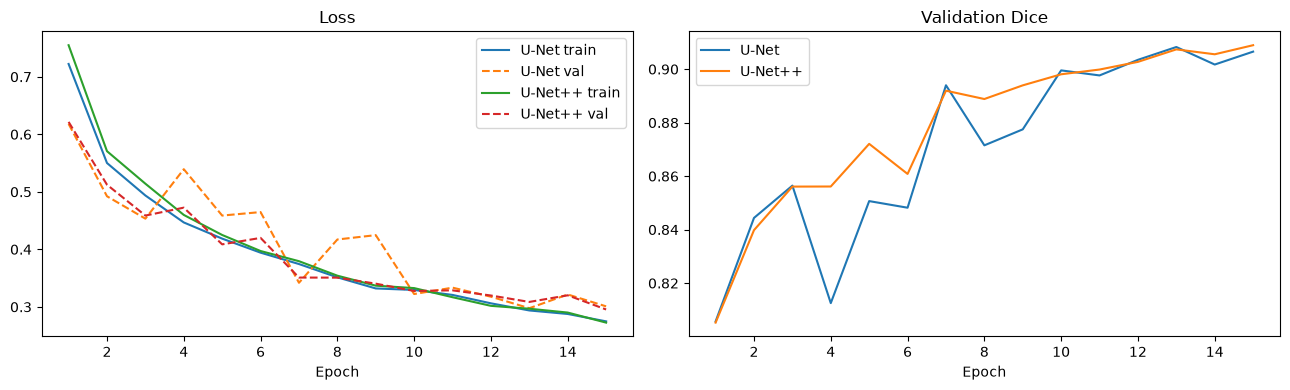

In [15]:
epochs_range = range(1, EPOCHS + 1)
fig, axes = plt.subplots(1, 2, figsize=(13, 4))

axes[0].plot(epochs_range, unet_history["train_loss"], label="U-Net train")
axes[0].plot(epochs_range, unet_history["val_loss"], "--", label="U-Net val")
axes[0].plot(epochs_range, unetpp_history["train_loss"], label="U-Net++ train")
axes[0].plot(epochs_range, unetpp_history["val_loss"], "--", label="U-Net++ val")
axes[0].set_title("Loss")
axes[0].set_xlabel("Epoch")
axes[0].legend()

axes[1].plot(epochs_range, unet_history["val_dice"], label="U-Net")
axes[1].plot(epochs_range, unetpp_history["val_dice"], label="U-Net++")
axes[1].set_title("Validation Dice")
axes[1].set_xlabel("Epoch")
axes[1].legend()

plt.tight_layout()
plt.show()

### Final test scores

Now we use the **test set** for the first time. These are the numbers to report.

In [16]:
_, unet_iou, unet_dice = evaluate(unet, test_loader)
_, unetpp_iou, unetpp_dice = evaluate(unetpp, test_loader)

print(f"{'Model':10s} {'Test IoU':>9s} {'Test Dice':>10s} {'Params':>12s} {'Train time':>11s}")
print("-" * 56)
print(f"{'U-Net':10s} {unet_iou:9.4f} {unet_dice:10.4f} {count_parameters(unet):12,} {unet_minutes:9.1f} m")
print(f"{'U-Net++':10s} {unetpp_iou:9.4f} {unetpp_dice:10.4f} {count_parameters(unetpp):12,} {unetpp_minutes:9.1f} m")

Model       Test IoU  Test Dice       Params  Train time
--------------------------------------------------------
U-Net         0.8316     0.9011    7,849,601      34.9 m
U-Net++       0.8399     0.9067    9,159,681      39.9 m


### Predictions side by side

Look especially at the **edges**: ears, tails and legs. That's where the extra skip paths of U-Net++ are supposed to help.

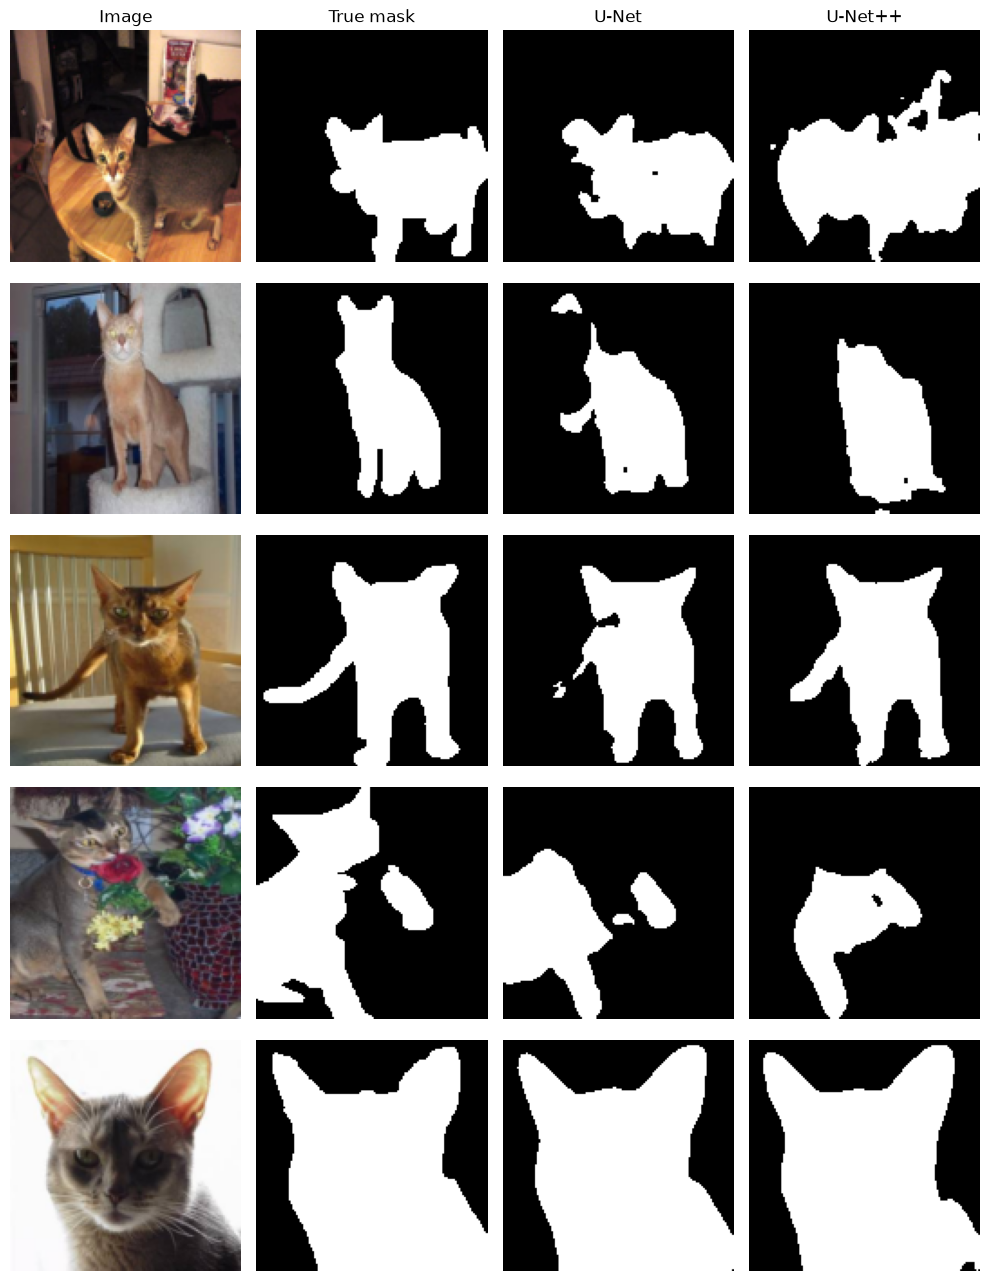

In [17]:
@torch.no_grad()
def predict(model, images):
    model.eval()
    logits = model(images.to(device))
    return (torch.sigmoid(logits) > 0.5).float().cpu()

images, masks = next(iter(test_loader))
unet_preds = predict(unet, images)
unetpp_preds = predict(unetpp, images)

titles = ["Image", "True mask", "U-Net", "U-Net++"]
fig, axes = plt.subplots(5, 4, figsize=(10, 13))
for row in range(5):
    axes[row, 0].imshow(images[row].permute(1, 2, 0))
    axes[row, 1].imshow(masks[row, 0], cmap="gray")
    axes[row, 2].imshow(unet_preds[row, 0], cmap="gray")
    axes[row, 3].imshow(unetpp_preds[row, 0], cmap="gray")
    for col in range(4):
        axes[row, col].axis("off")
        if row == 0:
            axes[row, col].set_title(titles[col])
plt.tight_layout()
plt.show()

## 9. Conclusion

### Results (test set, 3,669 images)

| Model | Test IoU | Test Dice | Parameters | Training time (15 epochs, Apple M4 Pro GPU) |
|---|---|---|---|---|
| U-Net | 0.8316 | 0.9011 | 7.85 M | 34.9 min |
| **U-Net++** | **0.8399** | **0.9067** | 9.16 M | 39.9 min |

### 1. Which model is better?
**U-Net++ scored higher on both metrics**, but the gap is small: **+0.83 IoU points** and **+0.56 Dice points**. Both models learned the task well. A Dice score above 0.90 means the predicted pet shape and the true shape overlap by more than 90%.

This matches the idea behind U-Net++. The nested skip connections pass the encoder features through extra conv blocks before they reach the decoder, which reduces the *semantic gap* between them and gives slightly better masks. On an easy two-class task like pet vs. background, plain U-Net is already strong, so there isn't much room left to improve.

### 2. Training behaviour
The training curves show a clearer difference than the final scores:
- **U-Net's validation score was unstable.** Validation Dice dropped sharply at epoch 4 (0.857 → 0.813) and again at epoch 8, and validation loss jumped up at the same points.
- **U-Net++ improved smoothly**, setting a new best validation score in 11 of the 15 epochs.
- **No overfitting:** for both models, validation loss stayed close to training loss until the end.
- **U-Net++ was still improving at the final epoch** (best score at epoch 15), while U-Net peaked at epoch 13. With more epochs the gap would probably grow a little.

A likely reason for the smoother training: every decoder block in U-Net++ receives features from several earlier blocks at its level, so gradients have more short paths to flow back through, which makes learning more stable.

### 3. Is the improvement worth the cost?
U-Net++ needs **17% more parameters** and took about **14% longer to train** (the timing is approximate, because another job was sharing the GPU while U-Net++ trained). Its memory use is also higher, because it stores many intermediate feature maps.
- For this pet task, a +0.6 Dice gain is **probably not worth it**. U-Net gives nearly the same result more cheaply.
- In **medical imaging**, where a small boundary error can matter (for example, the stroke lesion paper from Part 1), the more accurate and more stable U-Net++ is more useful.

### 4. Where do the models make mistakes?
Looking at the prediction grid:
- **Plain backgrounds are easy:** on the close-up cat against a white wall, both models are almost perfect.
- **Thin parts:** on the cat with the long tail, **U-Net++ captured most of the tail while U-Net missed it completely**. This is the kind of fine detail the dense skip connections are meant to keep.
- **Cluttered backgrounds are the main weakness of both models:** objects with similar colour or texture to the pet (a bag, a cat tree, a flower pot) were partly labelled as pet.
- **Neither model wins on every image:** U-Net++ is better on average, but in some images (the cat sitting on the cat tree, the cat among the flowers) U-Net's mask was actually closer, and U-Net++ cut off part of the head or body.
- **Low resolution:** images were resized to 128×128 to keep training fast, so small details like ear tips, paws and whiskers lose pixels before the model even sees them.

### 5. What I learned
- Building both models from the same `DoubleConv` block made it clear that **the only real difference between U-Net and U-Net++ is how the skip connections are designed**.
- Using one shared training function, a fixed seed and a held-out test set was essential for a **fair comparison**. Otherwise a difference this small could just be random noise.
- Saving the **best model by validation score** (instead of the last epoch) mattered: U-Net's last epoch was worse than its best.


### References
1. Ronneberger, O., Fischer, P., Brox, T. (2015). *U-Net: Convolutional Networks for Biomedical Image Segmentation.* MICCAI.
2. Zhou, Z., Siddiquee, M. M. R., Tajbakhsh, N., Liang, J. (2018). *UNet++: A Nested U-Net Architecture for Medical Image Segmentation.* DLMIA.
3. Parkhi, O. M., Vedaldi, A., Zisserman, A., Jawahar, C. V. (2012). *Cats and Dogs.* CVPR. (Oxford-IIIT Pet dataset)